# 01 · Known nominal trajectory
Propagate the supplied initial state and examine physical kinematics. No IOD is performed.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "configs" / "baseline.json").exists():
    ROOT = ROOT.parent
if not (ROOT / "configs" / "baseline.json").exists():
    raise RuntimeError("Open this notebook from the project root or notebooks directory")
sys.path.insert(0, str(ROOT / "src"))
from halo_tracking.study import load_config
cfg = load_config(ROOT / "configs" / "baseline.json")


## Input and conventions
The supplied SNRHL2 state is retained unchanged. The earlier northern-orbit goal remains unresolved. Values are rounded; orbit closure must be inspected. Model inertial axes are not ICRF.

In [2]:
cfg["orbit"]

Out[2]: 
{'catalog_id': 241,
 'catalog_secondary_id': 6,
 'family': 'SNRHL2',
 'period_tu': 1.8572,
 'stability_index': 1.6875,
 'state': [1.0444, -0.0277, -0.1879, -0.0329, -0.143, 0.081],
 'source_precision': 'four decimal places; not a corrected periodic solution'}


In [3]:
from halo_tracking.study import make_truth
result = make_truth(cfg)
result["config"] = cfg
result["diagnostics"]

Out[3]: 
{'period_closure_position_km': 99.11216130750401,
 'period_closure_velocity_km_s': 9.330359227914614e-05,
 'jacobi_range': 4.1675995987588976e-11,
 'visible_epochs': 45,
 'total_epochs': 389}


<ipython-input-3-5be5c964b5a3>:2: UserWarning: Supplied rounded state does not close within 1 km. Treat as an initial-value trajectory, not a validated periodic halo.
  result = make_truth(cfg)


## Geometry and physical derivatives
Acceleration includes the rotation terms when converting from the synodic frame. The site uses ideal synchronous rotation. Gateway geometry uses the reference state recovered from the earlier cislunar project.

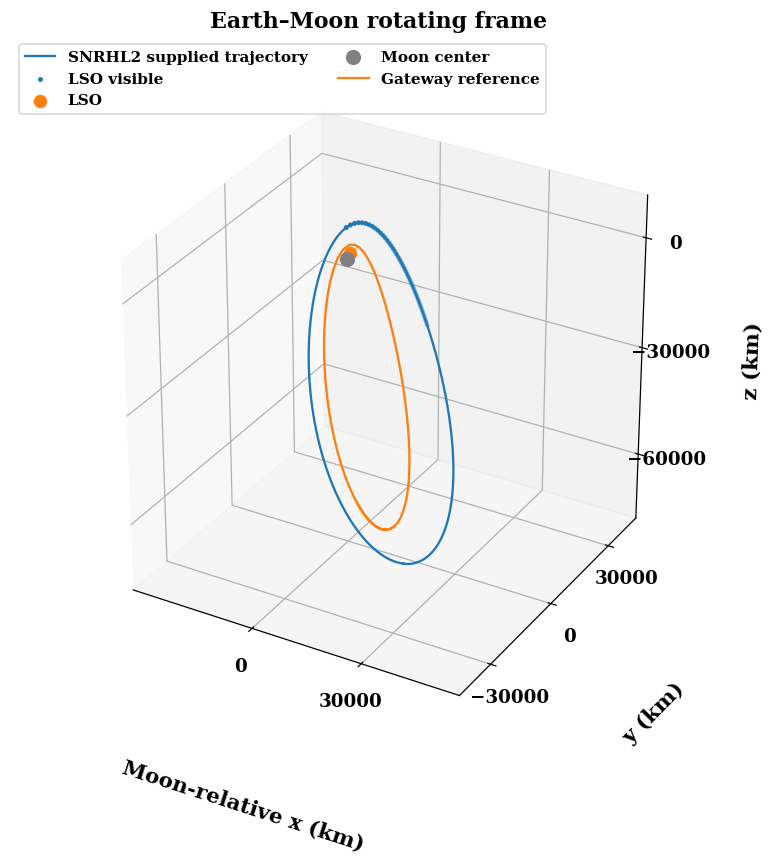

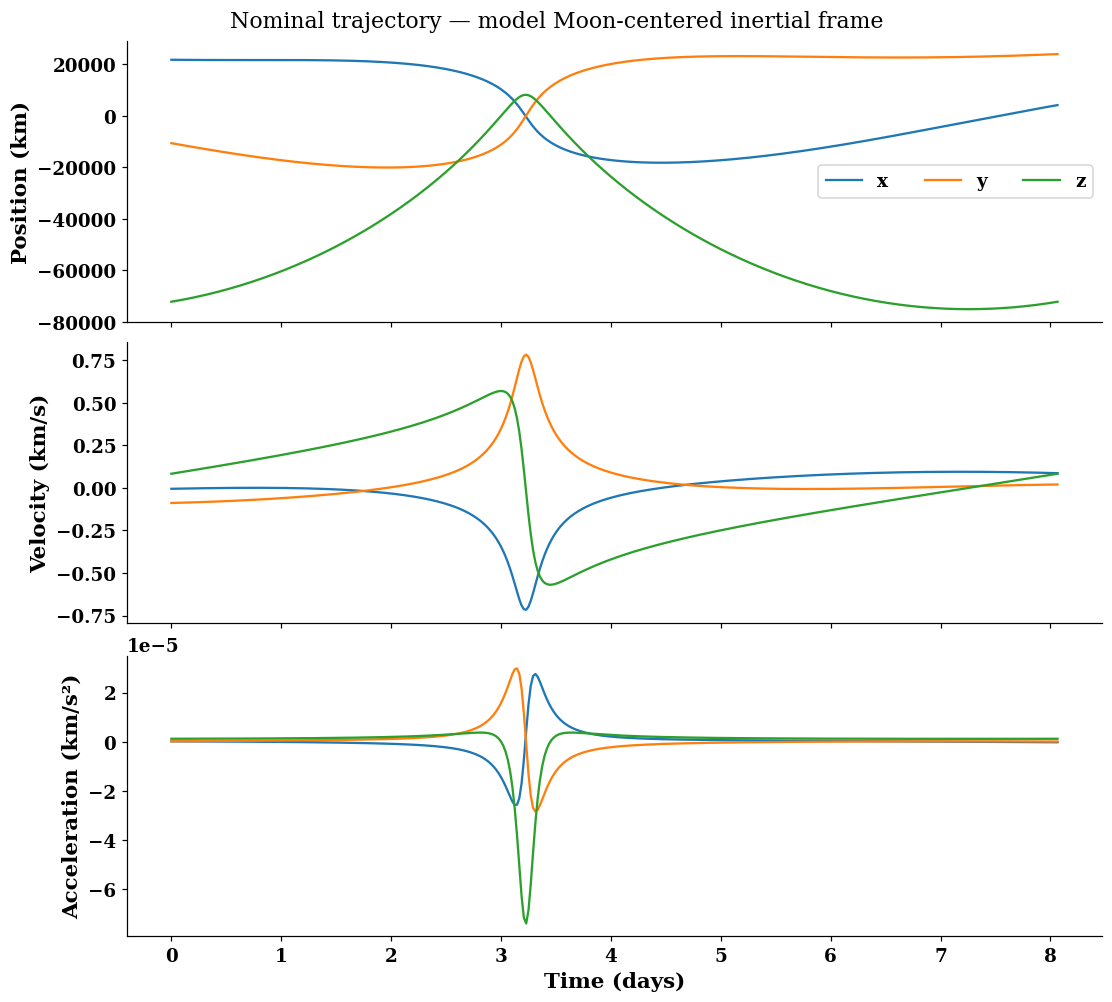

In [4]:
from halo_tracking.plotting import geometry, kinematics, export
fig_geometry = geometry(result)
fig_kinematics = kinematics(result)

In [5]:
export(fig_geometry, ROOT / "results/nominal/geometry.png")
export(fig_kinematics, ROOT / "results/nominal/kinematics.png")